# Models

In [37]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import config
from preprocessing import Preprocessor, remove_outliers
from evaluation import evaluate_model

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

## ML Models

In [10]:
train = pd.read_csv(config.paths.train_data)
test = pd.read_csv(config.paths.test_data)

X = train.drop(columns='SalePrice')
y = np.log(train['SalePrice'])

X, y = remove_outliers(X, y)

preprocessor = Preprocessor()

X_train = preprocessor.fit_transform(X, y)
X_test = preprocessor.transform(test)

print('Train:', X_train.shape)
print('Test:', X_test.shape)

Train: (1458, 37)
Test: (1459, 37)


In [11]:
score_calc = 'neg_root_mean_squared_error'

Baseline - линейная регрессия

In [12]:
parameters = {
    'model__fit_intercept': [True, False]
}

linreg_score = evaluate_model(LinearRegression(), parameters, X, y)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best score: 0.14135
Best params: {'model__fit_intercept': True}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model', LinearRegression())])


RMSE для бейзлайн решения - 0.14135

Ridge-регрессия:

In [13]:
parameters = {'model__alpha': np.logspace(-3, 3, 13), 'model__tol':[1e-06,5e-06,1e-05,5e-05]}

ridge_score = evaluate_model(Ridge(), parameters, X, y)

Fitting 5 folds for each of 52 candidates, totalling 260 fits
Best score: 0.13968
Best params: {'model__alpha': np.float64(3.1622776601683795), 'model__tol': 1e-06}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 Ridge(alpha=np.float64(3.1622776601683795), tol=1e-06))])


RMSE Ridge-регрессии: 0.13968

Lasso-регрессия:

In [16]:
parameters = {'model__alpha': np.logspace(-3, 3, 13), 'model__tol':[1e-06,1e-05,5e-05,1e-04,5e-04,1e-03]}

lasso_score = evaluate_model(Lasso(), parameters, X, y)

Fitting 5 folds for each of 78 candidates, totalling 390 fits
Best score: 0.14026
Best params: {'model__alpha': np.float64(0.001), 'model__tol': 5e-05}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model', Lasso(alpha=np.float64(0.001), tol=5e-05))])


RMSE Lasso-регрессии: 0.14026

ElasticNet-регрессия:

In [21]:
parameters = {'model__alpha' :[0.001, 0.01, 0.1,1.0,10], 'model__max_iter' :[1000000], 'model__l1_ratio':[0.04,0.05], 
              'model__fit_intercept' : [False,True], 'model__tol':[1e-02,1e-03,1e-04]}

elastic_net_score = evaluate_model(ElasticNet(), parameters, X, y)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best score: 0.13974
Best params: {'model__alpha': 0.001, 'model__fit_intercept': True, 'model__l1_ratio': 0.05, 'model__max_iter': 1000000, 'model__tol': 0.0001}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 ElasticNet(alpha=0.001, l1_ratio=0.05, max_iter=1000000))])


RMSE ElasticNet-регрессии: 0.13974

SGD-регрессия:

In [24]:
parameters = {'model__alpha' :[1e-05, 0.0001, 0.001, 0.01, 0.1], 'model__max_iter' :[10000], 
              'model__fit_intercept' : [False,True], 'model__epsilon':[0.001, 0.01, 0.1, 1]}

sgd_regressor_score = evaluate_model(SGDRegressor(), parameters, X, y)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best score: 0.14056
Best params: {'model__alpha': 0.0001, 'model__epsilon': 0.01, 'model__fit_intercept': True, 'model__max_iter': 10000}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model', SGDRegressor(epsilon=0.01, max_iter=10000))])


RMSE SGD-регрессии: 0.14056

Decision Tree:

In [27]:
parameters = { 'model__max_depth' : [7,8,9,10] , 'model__max_features' : [11,12,13,14] ,
               'model__max_leaf_nodes' : [None, 12,15,18,20] ,'model__min_samples_split' : [20,25,30],
                'model__random_state': [config.general.seed] }

decision_tree_score = evaluate_model(DecisionTreeRegressor(), parameters, X, y)    

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Best score: 0.19912
Best params: {'model__max_depth': 9, 'model__max_features': 14, 'model__max_leaf_nodes': None, 'model__min_samples_split': 25, 'model__random_state': 42}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 DecisionTreeRegressor(max_depth=9, max_features=14,
                                       min_samples_split=25,
                                       random_state=42))])


RMSE Decision Tree: 0.19912

Random Forest:

In [29]:
parameters = {'model__min_samples_split' : [3,4,6,10], 'model__n_estimators' : [70,100,300,500], 'model__random_state': [config.general.seed] }

random_forest_score = evaluate_model(RandomForestRegressor(), parameters, X, y)    

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best score: 0.15114
Best params: {'model__min_samples_split': 4, 'model__n_estimators': 500, 'model__random_state': 42}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 RandomForestRegressor(min_samples_split=4, n_estimators=500,
                                       random_state=42))])


RMSE Random Forest: 0.15114

XGBoost:

In [31]:
parameters = {'model__n_estimators': [300, 600, 1000], 'model__max_depth': [2, 3, 4],
    'model__learning_rate': [0.03, 0.05], 'model__min_child_weight': [1, 3],
    'model__subsample': [0.6, 0.8, 1.0], 'model__colsample_bytree': [0.6, 0.8, 1.0],
}

xgboost_score = evaluate_model(
    XGBRegressor(
        objective='reg:squarederror',
        random_state=config.general.seed,
        n_jobs=1,
        tree_method='hist'
    ),
    parameters,
    X,
    y
)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best score: 0.14157
Best params: {'model__colsample_bytree': 0.6, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_child_weight': 1, 'model__n_estimators': 300, 'model__subsample': 0.6}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=0.6, device=None,
                              early_stopping_rounds=None,
                              enable_categorical=True, eval_metric=None,
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                           

RMSE XGBoost: 0.14157

CatBoost:

In [34]:
parameters = {
    'model__iterations': [500, 1000, 1500],
    'model__depth': [4, 6],
    'model__learning_rate': [0.001, 0.01, 0.05, 0.1],
    'model__l2_leaf_reg': [3, 7],
}

catboost_score = evaluate_model(
    CatBoostRegressor(
        loss_function='RMSE',
        random_seed=config.general.seed,
        verbose=False,
        thread_count=1,
        allow_writing_files=False
    ),
    parameters,
    X,
    y
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best score: 0.13987
Best params: {'model__depth': 6, 'model__iterations': 1500, 'model__l2_leaf_reg': 3, 'model__learning_rate': 0.01}
Best estimator: Pipeline(steps=[('preprocessing', Preprocessor()),
                ('model',
                 CatBoostRegressor(allow_writing_files=False, depth=6, iterations=1500, l2_leaf_reg=3, learning_rate=0.01, loss_function='RMSE', random_seed=42, thread_count=1, verbose=False))])


RMSE Catboost: 0.13987

Сравним результаты различных ML-моделей:

In [35]:
list_scores = [linreg_score, ridge_score, lasso_score, elastic_net_score,
               sgd_regressor_score, decision_tree_score, random_forest_score, 
               xgboost_score, catboost_score]
list_regressors = ['Linear','Ridge','Lasso','ElaNet','SGD','DTr','RF','XGB','CatB']

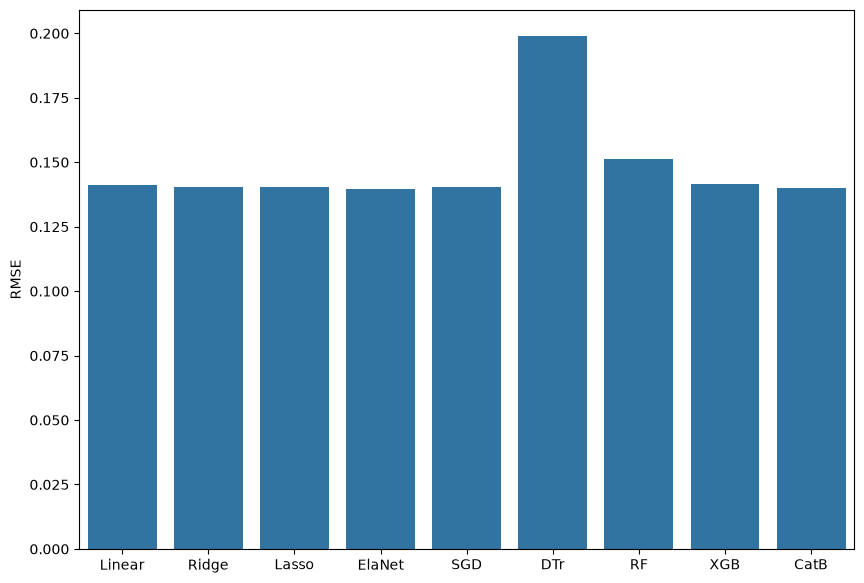

In [38]:
fig, ax = plt.subplots()
fig.set_size_inches(10,7)
sns.barplot(x=list_regressors, y=list_scores, ax=ax)
plt.ylabel('RMSE')
plt.show()

В целом линейные модели и бустинги показывают схожие результаты. Случайный лес показывает результат чуть хуже линейных моделей. Наихудшие предсказания наблюдаются у решающего дерева.